In [ ]:

!pip install ultralytics opencv-python-headless pandas matplotlib -q


In [ ]:

import cv2
import pandas as pd
import matplotlib.pyplot as plt
import os
from datetime import datetime
from ultralytics import YOLO
from google.colab import files
from IPython.display import display

print("Initializing VisionPort...")

model = YOLO("yolov8n.pt")

print("VisionPort initialized successfully!")
print("Object Detection System is ready.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Initializing VisionPort...
VisionPort initialized successfully!
Object Detection System is ready.


In [ ]:

def detect_objects(image_path, confidence=0.4):

    image = cv2.imread(image_path)

    if image is None:
        print("Unable to read image.")
        return None, []

    results = model.predict(
        source=image,
        conf=confidence,
        verbose=False
    )

    result = results[0]
    output = result.plot()

    detections = []

    for box in result.boxes:

        class_id = int(box.cls[0])
        object_name = model.names[class_id]

        score = float(box.conf[0])

        x1, y1, x2, y2 = map(
            int, box.xyxy[0].tolist()
        )

        detections.append({
            "Object": object_name,
            "Confidence (%)": round(score * 100, 2),
            "X1": x1,
            "Y1": y1,
            "X2": x2,
            "Y2": y2
        })

    return output, detections

print("Detection function created!")


Detection function created!


In [ ]:

print("Upload an image for VisionPort detection")

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

print("Image uploaded:", image_path)


Upload an image for VisionPort detection


Saving jo.jpeg to jo.jpeg
Image uploaded: jo.jpeg


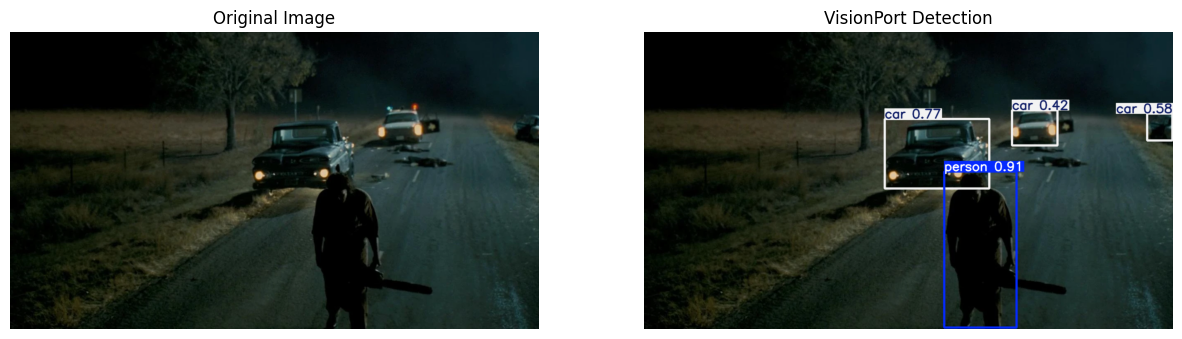

Total Objects Detected: 4


In [ ]:

output, detections = detect_objects(
    image_path,
    confidence=0.4
)

if output is not None:

    original = cv2.imread(image_path)
    original = cv2.cvtColor(
        original, cv2.COLOR_BGR2RGB
    )

    detected = cv2.cvtColor(
        output, cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(15, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(original)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(detected)
    plt.title("VisionPort Detection")
    plt.axis("off")

    plt.show()

    print("Total Objects Detected:", len(detections))
